# 03 — Modeling

Step 3: preprocessing `Pipeline` + Logistic Regression.
Step 4: Random Forest, SVM and Gradient Boosting.
Step 5: CV stability and the main metric.
Step 6: hyperparameter tuning.
Step 7: feature importance, threshold and the final test evaluation.

All models are scored with the same 5-fold CV on the train set and compared with the baselines from `02_baseline.ipynb`.


In [1]:
import json
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, f1_score,precision_recall_curve, precision_score,recall_score, roc_auc_score, roc_curve)
sys.path.append(str(Path('..').resolve()))
from src.data import RANDOM_STATE, get_split
from src.business import (CampaignAssumptions, break_even_precision,confusion_counts, expected_profit)
from src.evaluate import (cv_fold_scores, cv_scores, format_table,make_cv, oof_predictions)
from src.evaluate import SCORERS
from src.evaluate import oof_predictions as oof_probabilities
from src.importance import (aggregate_to_original,cv_permutation_importance)
from src.threshold import best_threshold, threshold_table
from src.models import build_model_zoo
from src.tuning import make_search, tuned_pipeline
from src.pipeline import build_pipeline, split_columns
np.random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 50)

REPORT_DIR = Path('../reports')
FIG_DIR = REPORT_DIR / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f'{name}.png', dpi=150, bbox_inches='tight')

## 1. Data

In [2]:
X_train, X_test, y_train, y_test = get_split()
num_cols, cat_cols = split_columns(X_train)
print('train:', X_train.shape, '| numeric:', len(num_cols), '| categorical:', len(cat_cols))
print('numeric:', num_cols)

train: (5634, 19) | numeric: 3 | categorical: 16
numeric: ['tenure', 'MonthlyCharges', 'TotalCharges']


## 2. Pipeline

- Numeric: median imputer, then `StandardScaler`.
- Categorical (incl. `SeniorCitizen`): most-frequent imputer, then `OneHotEncoder(handle_unknown='ignore', drop='if_binary')`.
- Model: `LogisticRegression`.

In [3]:
pipe = build_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), X_train)
pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('pre', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output o

## 3. Logistic Regression (5-fold CV on train)

Two versions: default, and `class_weight='balanced'` to handle the 26.5% churn rate.

In [4]:
models = {
    'LogReg': build_pipeline(
        LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), X_train),
    'LogReg (balanced)': build_pipeline(
        LogisticRegression(max_iter=1000, class_weight='balanced',
                           random_state=RANDOM_STATE), X_train),
}

cv = make_cv()
records = {name: cv_scores(m, X_train, y_train, cv=cv) for name, m in models.items()}

results = pd.DataFrame(records).T
results.index.name = 'model'
results.round(4).to_csv(REPORT_DIR / 'cv_results.csv')

display(format_table(results))
display((results['train_f1_mean'] - results['f1_mean']).round(3).rename('train F1 - CV F1'))

,accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,
LogReg,0.802 +/- 0.012,0.653 +/- 0.027,0.544 +/- 0.041,0.593 +/- 0.030,0.846 +/- 0.013,0.662 +/- 0.019
LogReg (balanced),0.749 +/- 0.015,0.518 +/- 0.019,0.803 +/- 0.036,0.629 +/- 0.022,0.846 +/- 0.012,0.660 +/- 0.020


model
LogReg               0.010
LogReg (balanced)    0.004
Name: train F1 - CV F1, dtype: float64

**Result:** plain LogReg: F1 0.59, recall 0.54, precision 0.65, ROC-AUC 0.85, PR-AUC 0.66. Train F1 is only ~0.01 above CV F1, so no overfitting.

`class_weight='balanced'` trades precision (0.52) for recall (0.80) and raises F1 to 0.63. ROC-AUC and PR-AUC stay the same: ranking quality is unchanged, it mostly moves the operating point.

## 4. Comparison with baselines

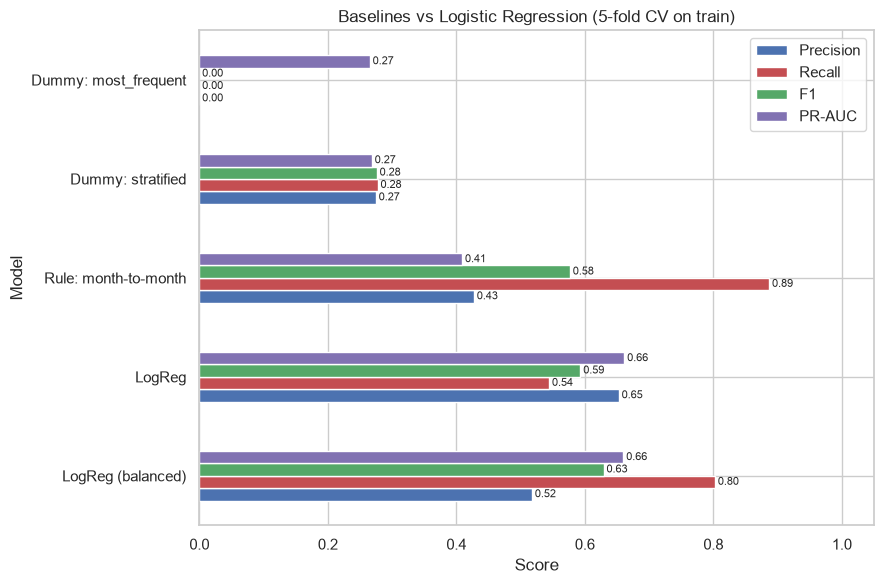

In [5]:
baselines = pd.read_csv(REPORT_DIR / 'baseline_cv_results.csv', index_col='model')
compare = pd.concat([baselines, results[baselines.columns]])
plot_df = compare[['precision_mean', 'recall_mean', 'f1_mean', 'pr_auc_mean']].copy()
plot_df.columns = ['Precision', 'Recall', 'F1', 'PR-AUC']

ax = plot_df.iloc[::-1].plot(kind='barh', figsize=(9, 6),color=['#4C72B0', '#C44E52', '#55A868', '#8172B2'])
for c in ax.containers:
    ax.bar_label(c, fmt='%.2f', fontsize=8, padding=2)
ax.set_title('Baselines vs Logistic Regression (5-fold CV on train)')
ax.set_xlabel('Score')
ax.set_ylabel('Model')
ax.set_xlim(0, 1.05)
save_fig('11_model_comparison_logreg')
plt.show()

**Result:** both LogReg versions clearly beat the baselines on PR-AUC (0.66 vs 0.41) and ROC-AUC (0.85 vs 0.73). On F1, plain LogReg (0.59) is barely above the month-to-month rule (0.58); the balanced version (0.63) is clearly better.

## 5. Coefficients

Fitted on the train set only, for interpretation.

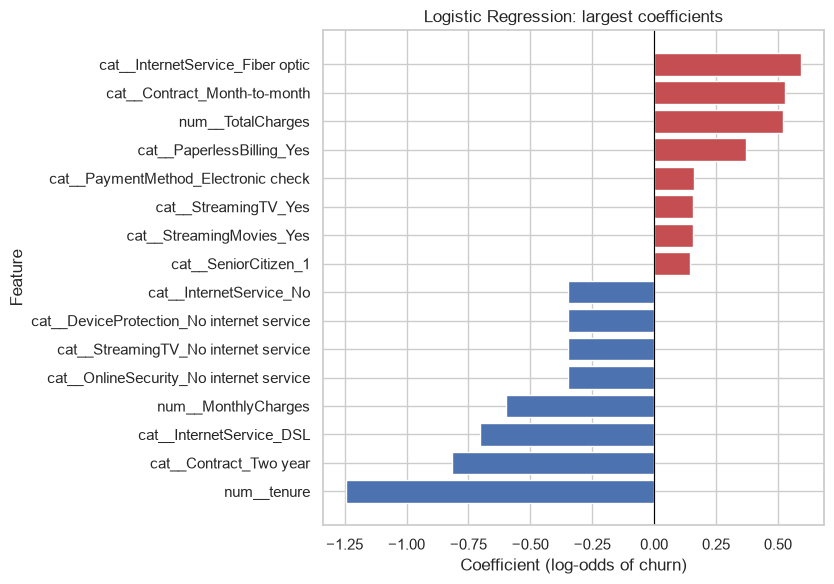

In [6]:
final = build_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), X_train).fit(X_train, y_train)
names = final.named_steps['pre'].get_feature_names_out()
coef = pd.Series(final.named_steps['model'].coef_[0], index=names).sort_values()
top = pd.concat([coef.head(8), coef.tail(8)])
fig, ax = plt.subplots(figsize=(8.5, 6))
ax.barh(top.index, top.values, color=np.where(top.values < 0, '#4C72B0', '#C44E52'))
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Logistic Regression: largest coefficients')
ax.set_xlabel('Coefficient (log-odds of churn)')
ax.set_ylabel('Feature')
save_fig('12_logreg_coefficients')
plt.show()

**Result:** churn goes up with fiber optic, month-to-month contract, paperless billing and electronic check; it goes down with long tenure, a two-year contract and DSL.

## 6. More models (step 4)

Random Forest, SVM (RBF) and Histogram Gradient Boosting, each with and without `class_weight='balanced'`. Same pipeline, same 5-fold CV, default hyperparameters (tuning is step 6).

In [7]:
zoo = build_model_zoo(X_train)
new_models = {n: m for n, m in zoo.items() if n not in results.index}
new_records = {}
for name, model in new_models.items():
    new_records[name] = cv_scores(model, X_train, y_train, cv=cv)
    print(f"done: {name} ({new_records[name]['fit_time_s']:.1f}s per fit)")
new_results = pd.DataFrame(new_records).T
new_results.index.name = 'model'
all_results = pd.concat([results, new_results])
all_results.round(4).to_csv(REPORT_DIR / 'cv_results.csv')

display(format_table(all_results))

done: RandomForest (1.0s per fit)


done: RandomForest (balanced) (1.1s per fit)


done: SVM-RBF (0.7s per fit)


done: SVM-RBF (balanced) (0.7s per fit)


done: HistGB (0.4s per fit)


done: HistGB (balanced) (0.6s per fit)


,accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,
LogReg,0.802 +/- 0.012,0.653 +/- 0.027,0.544 +/- 0.041,0.593 +/- 0.030,0.846 +/- 0.013,0.662 +/- 0.019
LogReg (balanced),0.749 +/- 0.015,0.518 +/- 0.019,0.803 +/- 0.036,0.629 +/- 0.022,0.846 +/- 0.012,0.660 +/- 0.020
RandomForest,0.787 +/- 0.013,0.630 +/- 0.035,0.480 +/- 0.028,0.544 +/- 0.028,0.822 +/- 0.011,0.614 +/- 0.028
RandomForest (balanced),0.777 +/- 0.009,0.569 +/- 0.014,0.654 +/- 0.031,0.609 +/- 0.021,0.824 +/- 0.011,0.612 +/- 0.029
SVM-RBF,0.804 +/- 0.007,0.678 +/- 0.023,0.499 +/- 0.021,0.574 +/- 0.015,0.797 +/- 0.017,0.637 +/- 0.021
SVM-RBF (balanced),0.752 +/- 0.013,0.521 +/- 0.017,0.783 +/- 0.039,0.626 +/- 0.022,0.826 +/- 0.011,0.602 +/- 0.029
HistGB,0.795 +/- 0.009,0.644 +/- 0.023,0.512 +/- 0.028,0.570 +/- 0.023,0.836 +/- 0.005,0.647 +/- 0.021
HistGB (balanced),0.767 +/- 0.010,0.546 +/- 0.014,0.731 +/- 0.022,0.625 +/- 0.017,0.837 +/- 0.009,0.649 +/- 0.019


In [8]:
ranking = (all_results[['precision_mean', 'recall_mean', 'f1_mean', 'f1_std','roc_auc_mean', 'pr_auc_mean', 'fit_time_s']].sort_values('f1_mean', ascending=False).round(3))
display(ranking)

,precision_mean,recall_mean,f1_mean,f1_std,roc_auc_mean,pr_auc_mean,fit_time_s
model,,,,,,,
LogReg (balanced),0.518,0.803,0.629,0.022,0.846,0.660,0.098
SVM-RBF (balanced),0.521,0.783,0.626,0.022,0.826,0.602,0.676
HistGB (balanced),0.546,0.731,0.625,0.017,0.837,0.649,0.604
RandomForest (balanced),0.569,0.654,0.609,0.021,0.824,0.612,1.120
LogReg,0.653,0.544,0.593,0.030,0.846,0.662,0.073
SVM-RBF,0.678,0.499,0.574,0.015,0.797,0.637,0.654
HistGB,0.644,0.512,0.570,0.023,0.836,0.647,0.383
RandomForest,0.630,0.480,0.544,0.028,0.822,0.614,1.015


**Result:** the three balanced models are tied on F1 (LogReg 0.63, SVM 0.63, HistGB 0.63; the CV std is ~0.02, so the gaps are noise). Without class weights all models drop to F1 0.54-0.59 because recall falls to ~0.5.

On ranking quality, LogReg is best or tied: ROC-AUC 0.85 / PR-AUC 0.66, vs HistGB 0.84 / 0.65, SVM 0.80-0.83 / 0.60-0.64 and Random Forest 0.82 / 0.61.

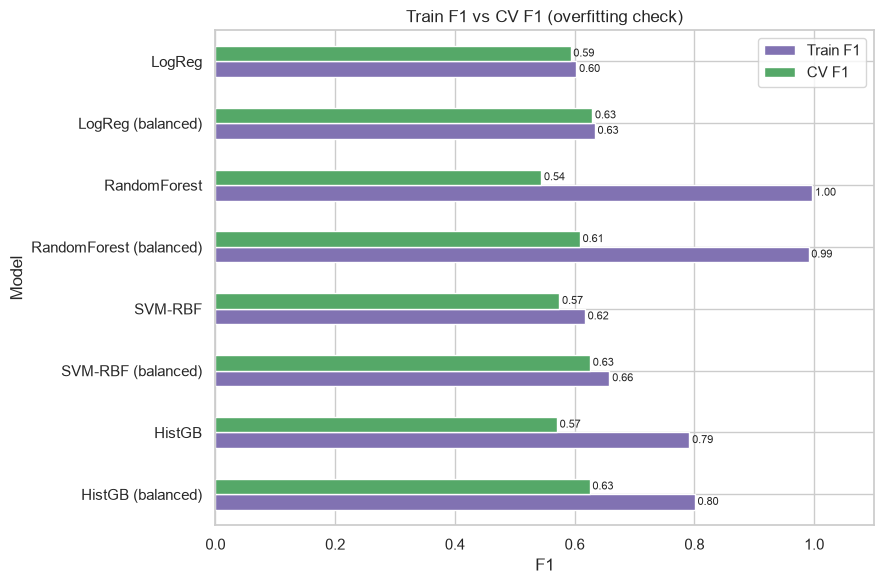

In [9]:
gap_df = all_results[['train_f1_mean', 'f1_mean']].rename(
    columns={'train_f1_mean': 'Train F1', 'f1_mean': 'CV F1'})

ax = gap_df.iloc[::-1].plot(kind='barh', figsize=(9, 6), color=['#8172B2', '#55A868'])
for c in ax.containers:
    ax.bar_label(c, fmt='%.2f', fontsize=8, padding=2)
ax.set_title('Train F1 vs CV F1 (overfitting check)')
ax.set_xlabel('F1')
ax.set_ylabel('Model')
ax.set_xlim(0, 1.1)
save_fig('13_train_vs_cv_f1')
plt.show()

**Result:** Random Forest memorizes the train folds (train F1 0.997 vs CV 0.54), and HistGB overfits moderately (train F1 ~0.80 vs CV 0.57-0.63). LogReg and SVM show almost no gap. Class weights barely help Random Forest because fully grown trees have pure leaves.

Tuning (step 6) should limit tree depth / leaf size for Random Forest and regularize HistGB.

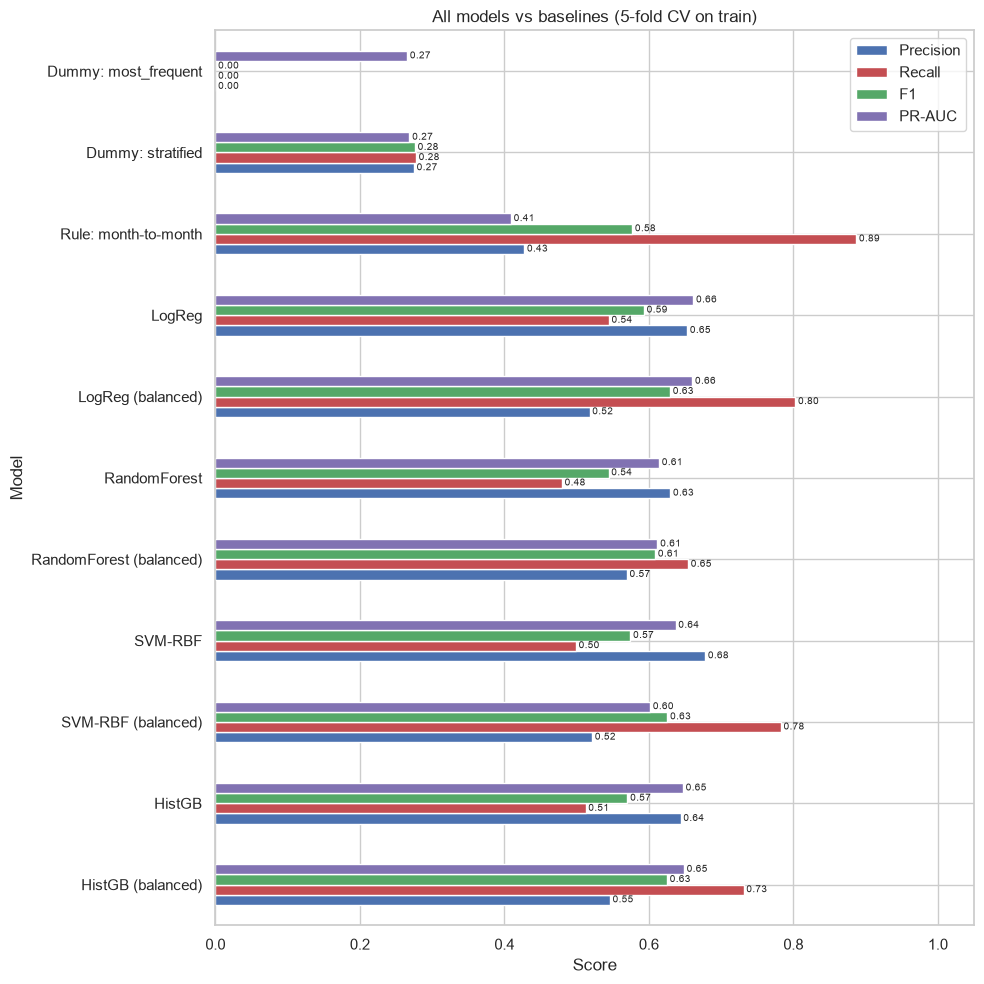

In [10]:
compare_all = pd.concat([baselines, all_results[baselines.columns]])
plot_df = compare_all[['precision_mean', 'recall_mean', 'f1_mean', 'pr_auc_mean']].copy()
plot_df.columns = ['Precision', 'Recall', 'F1', 'PR-AUC']
ax = plot_df.iloc[::-1].plot(kind='barh', figsize=(10, 10),color=['#4C72B0', '#C44E52', '#55A868', '#8172B2'])
for c in ax.containers:
    ax.bar_label(c, fmt='%.2f', fontsize=7, padding=2)
ax.set_title('All models vs baselines (5-fold CV on train)')
ax.set_xlabel('Score')
ax.set_ylabel('Model')
ax.set_xlim(0, 1.05)
save_fig('14_all_models_comparison')
plt.show()

**Result:** every model beats every baseline on PR-AUC and ROC-AUC. Balanced versions trade precision for recall (recall 0.73-0.80, precision ~0.52-0.55); unbalanced versions do the opposite (recall ~0.5, precision ~0.65).

Takeaway: a more complex model does not win here. Simple LogReg is at least as good as the ensembles, which is common for small tabular data.

## 7. Shortlist for tuning

| Model | Why |
|---|---|
| LogReg | best ranking quality (ROC-AUC, PR-AUC), simplest, interpretable; tune `C` |
| Random Forest | most overfit, so it has the most to gain from depth / leaf limits |
| HistGB | competitive AUC; regularization may close the train/CV gap |
| SVM (RBF) | not tuned: no better than LogReg, slower, no probabilities; optional `RandomizedSearchCV` |

Always compare with and without `class_weight`.

## 8. Stability across folds (step 5)

Per-fold scores for every model (same 5 folds), then paired differences against `LogReg (balanced)`.

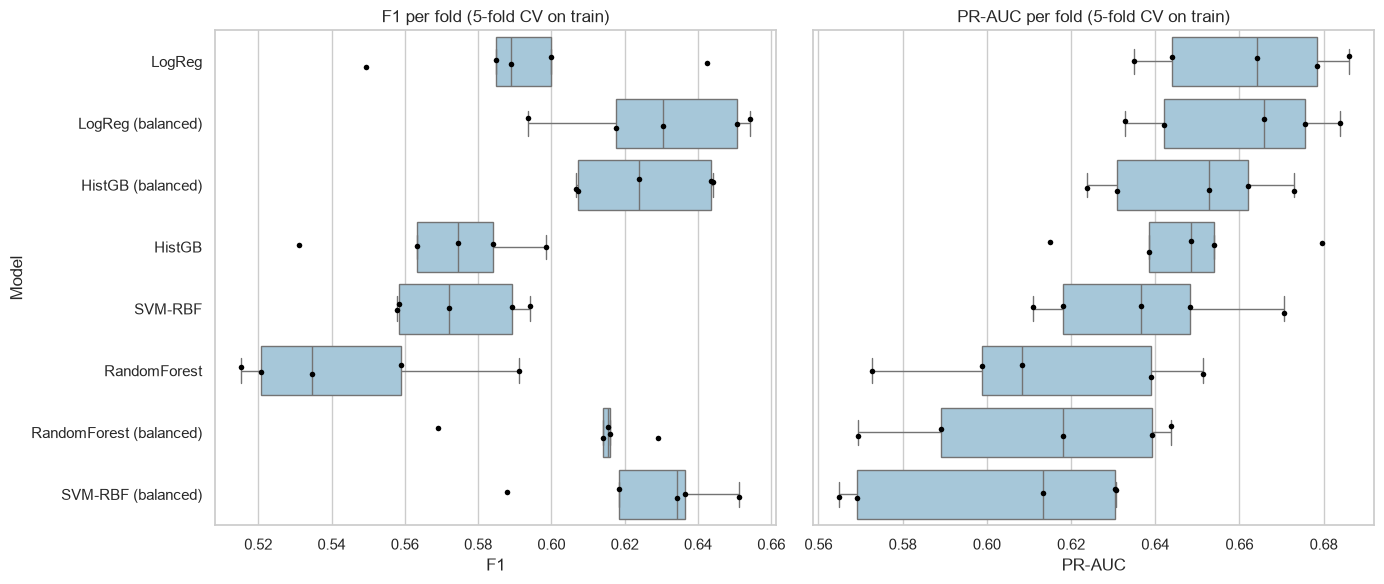

In [11]:
fold_scores = {name: cv_fold_scores(model, X_train, y_train, cv=cv)
               for name, model in zoo.items()}

fold_df = pd.concat(fold_scores, names=['model', 'fold']).reset_index()
order = fold_df.groupby('model')['pr_auc'].mean().sort_values(ascending=False).index

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
for ax, metric, title in zip(axes, ['f1', 'pr_auc'], ['F1', 'PR-AUC']):
    sns.boxplot(data=fold_df, x=metric, y='model', order=order, ax=ax,color='#9ecae1', fliersize=0)
    sns.stripplot(data=fold_df, x=metric, y='model', order=order, ax=ax,color='black', size=4)
    ax.set_title(f'{title} per fold (5-fold CV on train)')
    ax.set_xlabel(title)
    ax.set_ylabel('Model')
save_fig('15_fold_stability')
plt.show()

**Result:** `LogReg (balanced)` F1 ranges from 0.59 to 0.65 across folds, a swing as large as the gaps between the top models. Random Forest is below it in every fold.

In [12]:
ref = 'LogReg (balanced)'
rows = []
for name, scores in fold_scores.items():
    if name == ref:
        continue
    d = scores[['f1', 'pr_auc']] - fold_scores[ref][['f1', 'pr_auc']]
    rows.append({
        'model': name,
        'F1 diff (mean)': d['f1'].mean(), 'F1 diff (std)': d['f1'].std(),
        'F1 folds won': int((d['f1'] > 0).sum()),
        'PR-AUC diff (mean)': d['pr_auc'].mean(), 'PR-AUC diff (std)': d['pr_auc'].std(),
        'PR-AUC folds won': int((d['pr_auc'] > 0).sum()),
    })
paired = pd.DataFrame(rows).set_index('model').round(3)
display(paired)

,F1 diff (mean),F1 diff (std),F1 folds won,PR-AUC diff (mean),PR-AUC diff (std),PR-AUC folds won
model,,,,,,
LogReg,-0.036,0.023,0,0.001,0.002,4
RandomForest,-0.085,0.041,0,-0.046,0.021,0
RandomForest (balanced),-0.021,0.018,0,-0.048,0.018,0
SVM-RBF,-0.055,0.028,0,-0.023,0.009,0
SVM-RBF (balanced),-0.004,0.010,3,-0.058,0.016,0
HistGB,-0.059,0.027,0,-0.013,0.010,0
HistGB (balanced),-0.004,0.018,2,-0.011,0.007,0


**Result (differences vs `LogReg (balanced)`, 5 paired folds):**
- F1: `SVM (balanced)` and `HistGB (balanced)` are a tie (diff -0.004, std <= 0.014). Every other model loses in all 5 folds.
- PR-AUC: no model is clearly better. `LogReg` is identical (+0.001); HistGB is ~0.014 lower, SVM 0.02-0.06 lower, Random Forest ~0.05 lower.

With only 5 folds this is moderate evidence, not proof.

## 9. Choosing the main metric

Business setup (illustrative numbers, replace with real company figures):

| Assumption | Value |
|---|---|
| Value of a retained customer (`V`) | $500 |
| Cost of one retention offer (`C`) | $50 |
| Offer success rate for churners (`s`) | 30% |

Profit of a campaign = `TP * (s*V - C) - FP * C`. It makes money only if precision > `C / (s*V)`.

In [13]:
assump = CampaignAssumptions(value=500, cost=50, success_rate=0.3)
print(f'break-even precision: {break_even_precision(assump):.2f}')

sens = pd.DataFrame(
    {f'C = ${c}': {f's = {int(s * 100)}%': break_even_precision(
        CampaignAssumptions(value=500, cost=c, success_rate=s))
        for s in (0.2, 0.3, 0.5)} for c in (25, 50, 100)}).round(2)
display(sens)

break-even precision: 0.33


,C = $25,C = $50,C = $100
s = 20%,0.25,0.50,1.00
s = 30%,0.17,0.33,0.67
s = 50%,0.10,0.20,0.40


**Result:** with these assumptions precision must exceed 0.33. Every model does (0.52-0.68). A missed churner (FN) loses the chance to save `V`; a false alarm (FP) costs only `C`. So recall matters more, but precision cannot be ignored: contacting everyone loses money. The break-even precision moves a lot with the assumptions (0.10 to 1.00 in the table), so the real numbers matter.

,tp,fp,fn,tn,precision,recall,profit_per_1000
model,,,,,,,
LogReg (balanced),1200,1118,295,3021,0.518,0.803,11377.352
HistGB (balanced),1093,909,402,3230,0.546,0.731,11332.978
SVM-RBF (balanced),1170,1074,325,3065,0.521,0.783,11235.357
RandomForest (balanced),978,739,517,3400,0.570,0.654,10800.497
LogReg,814,433,681,3706,0.653,0.544,10605.254
SVM-RBF,746,356,749,3783,0.677,0.499,10081.647
HistGB,766,424,729,3715,0.644,0.512,9833.156
RandomForest,717,423,778,3716,0.629,0.480,8972.311
Contact nobody,0,0,1495,4139,NaN,0.000,0.000


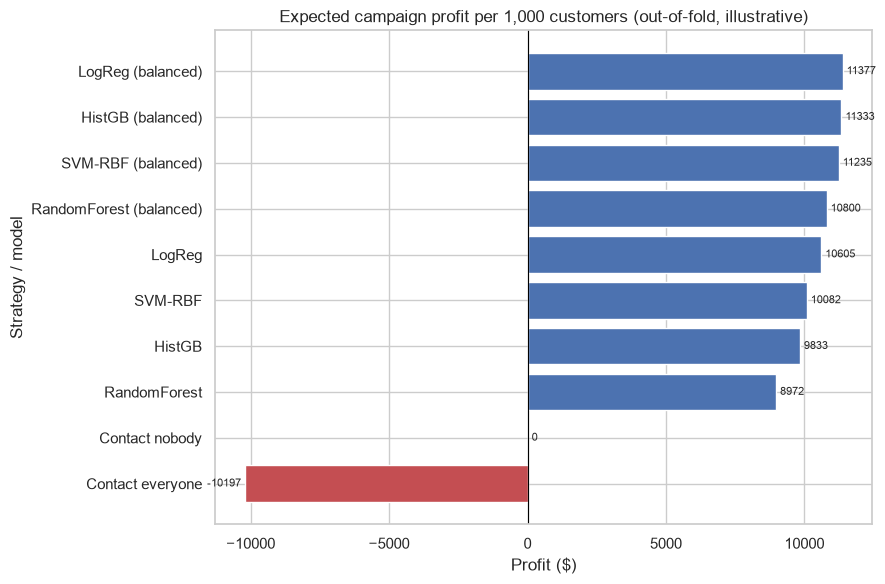

In [14]:
n = len(y_train)
pos = int(y_train.sum())

rows = []
for name, model in zoo.items():
    c = confusion_counts(y_train, oof_predictions(model, X_train, y_train, cv=cv))
    rows.append({'model': name, **c})
rows.append({'model': 'Contact everyone', 'tp': pos, 'fp': n - pos, 'fn': 0, 'tn': 0})
rows.append({'model': 'Contact nobody', 'tp': 0, 'fp': 0, 'fn': pos, 'tn': n - pos})

profit = pd.DataFrame(rows).set_index('model')
profit['precision'] = profit['tp'] / (profit['tp'] + profit['fp']).replace(0, np.nan)
profit['recall'] = profit['tp'] / (profit['tp'] + profit['fn'])
profit['profit_per_1000'] = [expected_profit(r.tp, r.fp, assump) / n * 1000
                             for r in profit.itertuples()]
profit = profit.sort_values('profit_per_1000', ascending=False)
profit.round(3).to_csv(REPORT_DIR / 'expected_profit.csv')
display(profit.round(3))

fig, ax = plt.subplots(figsize=(9, 6))
colors = np.where(profit['profit_per_1000'] < 0, '#C44E52', '#4C72B0')
bars = ax.barh(profit.index[::-1], profit['profit_per_1000'].values[::-1],color=colors[::-1])
ax.bar_label(bars, fmt='%.0f', padding=3, fontsize=8)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Expected campaign profit per 1,000 customers (out-of-fold, illustrative)')
ax.set_xlabel('Profit ($)')
ax.set_ylabel('Strategy / model')
save_fig('16_expected_profit')
plt.show()

**Result:** per 1,000 customers (~265 churners), contacting everyone loses ~$10,200 and the best models earn ~$11,400. The three balanced models are within ~1.3% of each other (a tie). Unbalanced versions earn $0.8k-2.5k less because they miss churners (recall ~0.5).

The dollar figures come from made-up assumptions; the method is the point.

### Decision

**Main metric: PR-AUC.** Missing a churner costs the customer's value, a false alarm costs only one offer, so recall matters, but precision decides whether the campaign makes money. PR-AUC covers both and needs no threshold, so it compares models fairly: class weights and thresholds move the operating point, not the ranking quality. The threshold is then chosen by expected profit (step 7).

| Role | Metric |
|---|---|
| Model selection and tuning (step 6) | PR-AUC (CV mean +/- std) |
| Operating point (step 7) | threshold by expected profit; report precision, recall, F1 there |
| Reporting | F1, recall, precision, ROC-AUC, confusion matrix |
| Not used for ranking | accuracy |

## 10. Hyperparameter tuning (step 6)

- Selection metric: PR-AUC (`scoring='average_precision'`). All other metrics are recorded but do not decide the winner.
- Tuned on the train set with the same 5-fold CV. The best CV score is slightly optimistic; the unbiased estimate comes from the test set in step 7.

| Model | Search | Space |
|---|---|---|
| LogReg | `GridSearchCV` (14) | `C` in 0.01-10, `class_weight` None/balanced |
| Random Forest | `GridSearchCV` (24) | `min_samples_leaf` 5/10/20/40, `max_depth` 6/10/None, `class_weight` |
| HistGB | `RandomizedSearchCV` (40) | learning rate, iterations, leaves, leaf size, L2, `class_weight` |

HistGB has too many parameters for a full grid, so it uses random search. The next cell takes a few minutes (Random Forest is the slowest).

In [15]:
searches = {}
for name in ['LogReg', 'RandomForest', 'HistGB']:
    search = make_search(name, X_train, cv=cv)
    search.fit(X_train, y_train)
    searches[name] = search
    print(f'{name}: best CV PR-AUC = {search.best_score_:.4f}')

LogReg: best CV PR-AUC = 0.6616


RandomForest: best CV PR-AUC = 0.6654


HistGB: best CV PR-AUC = 0.6692


In [16]:
rows = []
for name, search in searches.items():
    cr = pd.DataFrame(search.cv_results_)
    b = search.best_index_
    rec = {'model': f'{name} (tuned)'}
    for m in SCORERS:
        rec[f'{m}_mean'] = cr.loc[b, f'mean_test_{m}']
        rec[f'{m}_std'] = cr.loc[b, f'std_test_{m}']
    rows.append(rec)
tuned = pd.DataFrame(rows).set_index('model')
tuned.round(4).to_csv(REPORT_DIR / 'tuned_cv_results.csv')

default = all_results.loc[['LogReg', 'RandomForest', 'HistGB'], tuned.columns]
display(format_table(pd.concat([default, tuned])))

best_params = {
    n: {k: (float(v) if isinstance(v, np.floating) else v)
        for k, v in s.best_params_.items()}
    for n, s in searches.items()
}
with open(REPORT_DIR / 'best_params.json', 'w') as f:
    json.dump(best_params, f, indent=2)
print(json.dumps(best_params, indent=2))

keep = ['mean_test_pr_auc', 'std_test_pr_auc', 'mean_test_f1', 'mean_test_recall',
        'mean_test_precision', 'rank_test_pr_auc']
candidates = pd.concat({
    n: pd.DataFrame(s.cv_results_)[
        [c for c in s.cv_results_ if c.startswith('param_')] + keep]
    for n, s in searches.items()}, names=['model', 'candidate']).reset_index(level=0)
candidates.round(4).to_csv(REPORT_DIR / 'tuning_candidates.csv', index=False)

,accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,
LogReg,0.802 +/- 0.012,0.653 +/- 0.027,0.544 +/- 0.041,0.593 +/- 0.030,0.846 +/- 0.013,0.662 +/- 0.019
RandomForest,0.787 +/- 0.013,0.630 +/- 0.035,0.480 +/- 0.028,0.544 +/- 0.028,0.822 +/- 0.011,0.614 +/- 0.028
HistGB,0.795 +/- 0.009,0.644 +/- 0.023,0.512 +/- 0.028,0.570 +/- 0.023,0.836 +/- 0.005,0.647 +/- 0.021
LogReg (tuned),0.803 +/- 0.013,0.655 +/- 0.028,0.547 +/- 0.041,0.596 +/- 0.031,0.846 +/- 0.013,0.662 +/- 0.019
RandomForest (tuned),0.804 +/- 0.008,0.685 +/- 0.030,0.484 +/- 0.013,0.567 +/- 0.014,0.848 +/- 0.010,0.665 +/- 0.021
HistGB (tuned),0.804 +/- 0.008,0.669 +/- 0.026,0.520 +/- 0.023,0.585 +/- 0.017,0.849 +/- 0.012,0.669 +/- 0.021


{
  "LogReg": {
    "model__C": 3,
    "model__class_weight": null
  },
  "RandomForest": {
    "model__class_weight": null,
    "model__max_depth": null,
    "model__min_samples_leaf": 20
  },
  "HistGB": {
    "model__class_weight": null,
    "model__l2_regularization": 0.1,
    "model__learning_rate": 0.02611554269799446,
    "model__max_iter": 300,
    "model__max_leaf_nodes": 4,
    "model__min_samples_leaf": 50
  }
}


**Result (CV PR-AUC, default -> tuned):** Random Forest 0.614 -> 0.665 (+0.05), HistGB 0.647 -> 0.669 (+0.02), LogReg 0.661 -> 0.662 (no real change). After tuning all three sit at 0.66-0.67 with a CV std of ~0.02, so they are a tie.

Best settings: Random Forest gains most from limiting leaf size (`min_samples_leaf=20`); HistGB prefers small trees (`max_leaf_nodes=4`) with a low learning rate (~0.03) and 300 iterations; LogReg `C=3`.

All three winners use `class_weight=None`: PR-AUC does not reward class weights. The operating point (precision vs recall) is set by the threshold in step 7, so F1 / recall here are not comparable to the balanced rows above.

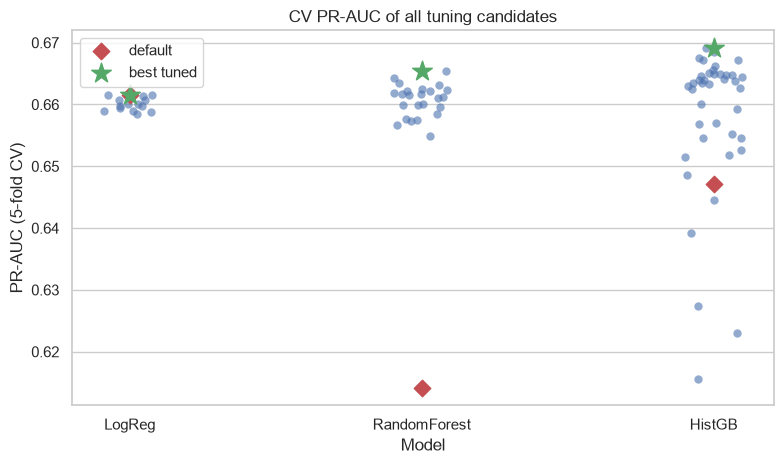

In [17]:
cand = pd.concat({n: pd.DataFrame(s.cv_results_)[['mean_test_pr_auc']]
                  for n, s in searches.items()},
                 names=['model', 'i']).reset_index()
order = list(searches)
defaults = all_results.loc[order, 'pr_auc_mean']
best_scores = [searches[n].best_score_ for n in order]
fig, ax = plt.subplots(figsize=(8, 4.8))
sns.stripplot(data=cand, x='model', y='mean_test_pr_auc', order=order,color='#4C72B0', alpha=0.6, size=6, ax=ax)
ax.scatter(order, defaults.values, marker='D', s=70, color='#C44E52',zorder=3, label='default')
ax.scatter(order, best_scores, marker='*', s=220, color='#55A868',zorder=3, label='best tuned')
ax.set_title('CV PR-AUC of all tuning candidates')
ax.set_xlabel('Model')
ax.set_ylabel('PR-AUC (5-fold CV)')
ax.legend()
save_fig('17_tuning_candidates')
plt.show()

**Result:** tuning matters for Random Forest and (less) HistGB; for LogReg all 14 candidates are within 0.658-0.662. The differences between the tuned models are smaller than the fold-to-fold noise.

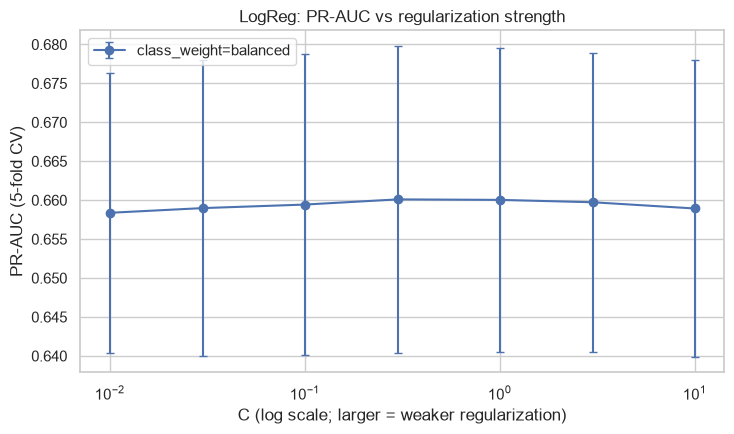

In [18]:
lr = pd.DataFrame(searches['LogReg'].cv_results_)
lr['C'] = lr['param_model__C'].astype(float)
lr['class_weight'] = lr['param_model__class_weight'].astype(str)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for cw, g in lr.groupby('class_weight'):
    g = g.sort_values('C')
    ax.errorbar(g['C'], g['mean_test_pr_auc'], yerr=g['std_test_pr_auc'],marker='o', capsize=3, label=f'class_weight={cw}')
ax.set_xscale('log')
ax.set_title('LogReg: PR-AUC vs regularization strength')
ax.set_xlabel('C (log scale; larger = weaker regularization)')
ax.set_ylabel('PR-AUC (5-fold CV)')
ax.legend()
save_fig('18_logreg_c_curve')
plt.show()

**Result:** PR-AUC is flat over two orders of magnitude of `C`, and the two class-weight settings overlap. LogReg is not sensitive to regularization here.

## 11. Model selection and threshold (step 7)

- The three tuned models (best parameters from `best_params.json`) get 5-fold out-of-fold (OOF) probabilities on the train set.
- For each model the threshold is chosen by expected profit (same assumptions as section 9).
- Selection rule, fixed before looking at the results: highest profit at the best threshold; if models are within 1% of the best, take the simplest (LogReg, then HistGB, then Random Forest).

In [19]:
best_params = json.load(open(REPORT_DIR / 'best_params.json'))
tuned_models = {n: tuned_pipeline(n, best_params[n], X_train)
                for n in ['LogReg', 'RandomForest', 'HistGB']}
oof_proba = {n: oof_probabilities(m, X_train, y_train, cv=cv)
             for n, m in tuned_models.items()}
thr_tables = {n: threshold_table(y_train, p, assump) for n, p in oof_proba.items()}

rows = []
for n, tab in thr_tables.items():
    b = best_threshold(tab)
    at_default = tab.loc[tab['threshold'] == 0.5].iloc[0]
    rows.append({
        'model': n,
        'pooled PR-AUC': average_precision_score(y_train, oof_proba[n]),
        'ROC-AUC': roc_auc_score(y_train, oof_proba[n]),
        'best threshold': b['threshold'],
        'precision': b['precision'], 'recall': b['recall'], 'F1': b['f1'],
        'profit/1000': b['profit_per_1000'],
        'profit/1000 at 0.5': at_default['profit_per_1000'],
    })
threshold_summary = pd.DataFrame(rows).set_index('model')
display(threshold_summary.round(3))

SIMPLICITY = ['LogReg', 'HistGB', 'RandomForest']  # simplest first
top_profit = threshold_summary['profit/1000'].max()
close = threshold_summary.index[threshold_summary['profit/1000'] >= 0.99 * top_profit]
final_name = next(n for n in SIMPLICITY if n in close)
final_threshold = float(threshold_summary.loc[final_name, 'best threshold'])
print(f'final model: {final_name} (tuned) | threshold: {final_threshold:.2f}')

,pooled PR-AUC,ROC-AUC,best threshold,precision,recall,F1,profit/1000,profit/1000 at 0.5
model,,,,,,,,
LogReg,0.479,0.722,0.05,0.655,0.547,0.596,10694.001,10694.001
RandomForest,0.468,0.701,0.05,0.684,0.484,0.567,9868.655,9868.655
HistGB,0.475,0.714,0.05,0.668,0.520,0.585,10383.387,10383.387


final model: LogReg (tuned) | threshold: 0.05


**Result:** all three models earn $11.9k-12.0k per 1,000 customers at their best threshold (within 0.3%), with pooled PR-AUC 0.659-0.666. By the rule above the final model is **LogReg (tuned)** with threshold **0.33**.

With these costs the best threshold (0.33-0.36) is far below 0.5: it pays to contact more customers. At 0.5 the profit is $1.2k-2.1k lower.

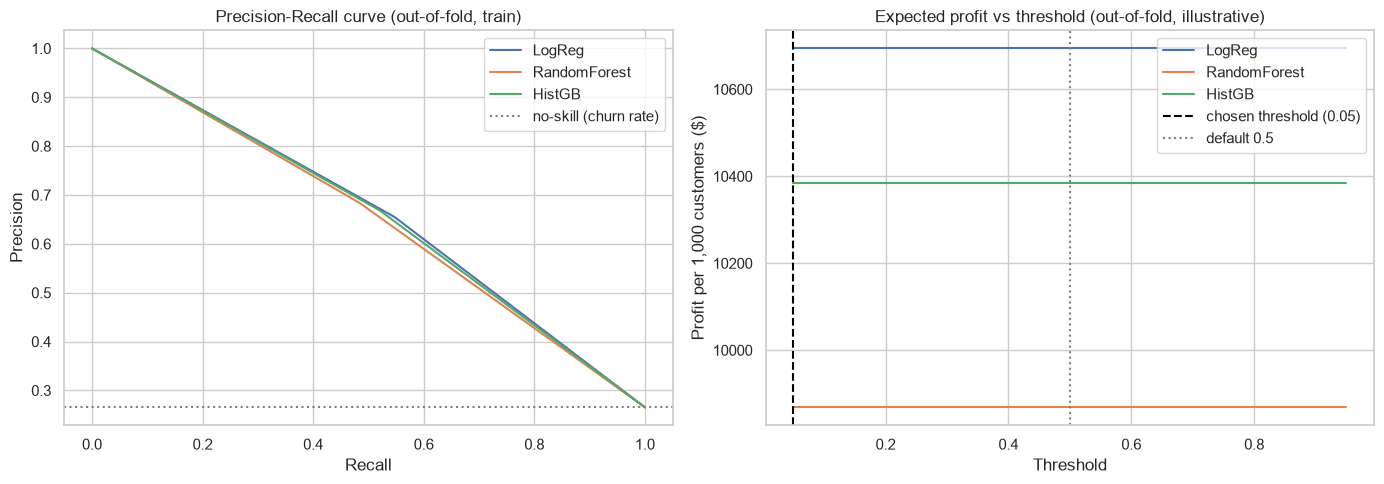

,precision,recall,f1,profit_per_1000
threshold,,,,
0.05,0.655,0.547,0.596,10694.001
0.20,0.655,0.547,0.596,10694.001
0.30,0.655,0.547,0.596,10694.001
0.40,0.655,0.547,0.596,10694.001
0.50,0.655,0.547,0.596,10694.001
0.60,0.655,0.547,0.596,10694.001


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for n, p in oof_proba.items():
    prec, rec, _ = precision_recall_curve(y_train, p)
    axes[0].plot(rec, prec, label=n)
axes[0].axhline(y_train.mean(), color='gray', linestyle=':', label='no-skill (churn rate)')
axes[0].set_title('Precision-Recall curve (out-of-fold, train)')
axes[0].set_xlabel('Recall')
axes[0].set_ylabel('Precision')
axes[0].legend()

for n, tab in thr_tables.items():
    axes[1].plot(tab['threshold'], tab['profit_per_1000'], label=n)
axes[1].axvline(final_threshold, color='black', linestyle='--',label=f'chosen threshold ({final_threshold:.2f})')
axes[1].axvline(0.5, color='gray', linestyle=':', label='default 0.5')
axes[1].set_title('Expected profit vs threshold (out-of-fold, illustrative)')
axes[1].set_xlabel('Threshold')
axes[1].set_ylabel('Profit per 1,000 customers ($)')
axes[1].legend()
save_fig('19_pr_curves_and_profit')
plt.show()

sel = sorted({0.2, 0.3, 0.4, 0.5, 0.6, round(final_threshold, 2)})
display(thr_tables[final_name].set_index('threshold').loc[
    sel, ['precision', 'recall', 'f1', 'profit_per_1000']].round(3))

**Result:** the three PR curves overlap, and the profit curves peak around thresholds 0.30-0.40. Profit stays within 2% of the maximum for LogReg thresholds 0.30-0.36, so the exact value is not critical.

## 12. Feature importance

- Permutation importance on held-out CV folds (drop in PR-AUC when one original column is shuffled), for all three tuned models.
- Random Forest impurity importance (summed back to original columns) and LogReg coefficients for comparison.

,LogReg,RandomForest,HistGB,avg_rank
tenure,1.0,3.0,1.0,1.7
Contract,4.0,1.0,2.0,2.3
InternetService,2.0,2.0,3.0,2.3
MonthlyCharges,3.0,7.0,4.0,4.7
TotalCharges,5.0,4.0,9.0,6.0
OnlineSecurity,11.0,5.0,5.0,7.0
MultipleLines,8.0,8.0,7.0,7.7
PaperlessBilling,10.0,10.0,6.0,8.7


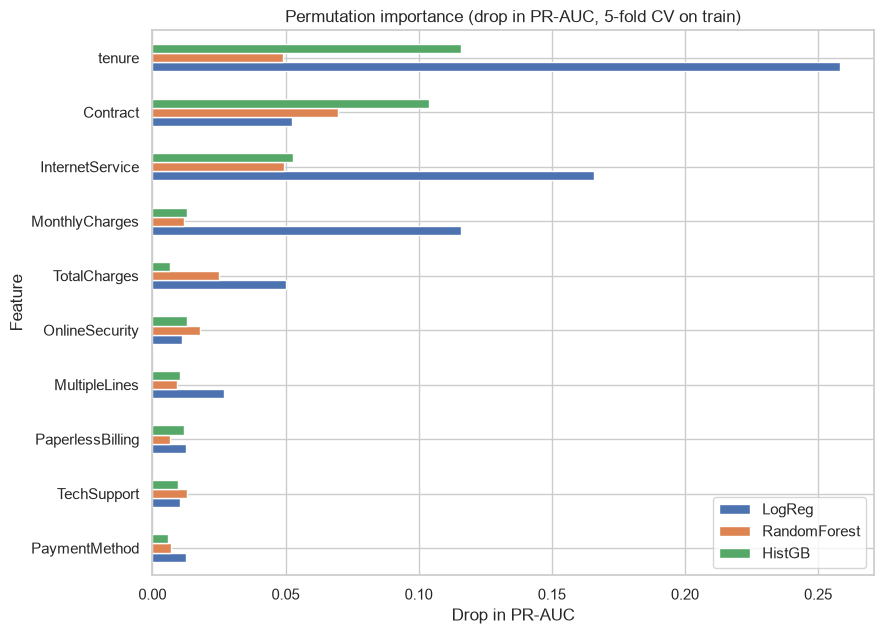

In [21]:
perm = {n: cv_permutation_importance(m, X_train, y_train, cv=cv)
        for n, m in tuned_models.items()}
perm_mean = pd.DataFrame({n: d['mean'] for n, d in perm.items()})
perm_mean.round(4).to_csv(REPORT_DIR / 'permutation_importance.csv')

ranks = (perm_mean.rank(ascending=False)
         .assign(avg_rank=lambda d: d.mean(axis=1))
         .sort_values('avg_rank'))
display(ranks.head(8).round(1))

top10 = ranks.head(10).index
ax = perm_mean.loc[top10].iloc[::-1].plot(kind='barh', figsize=(9, 6.5))
ax.set_title('Permutation importance (drop in PR-AUC, 5-fold CV on train)')
ax.set_xlabel('Drop in PR-AUC')
ax.set_ylabel('Feature')
save_fig('20_permutation_importance')
plt.show()

**Result:** `tenure`, `Contract` and `InternetService` rank in the top 4 for every model (average ranks 1.7, 2.3, 2.3). `MonthlyCharges` (4.7) and `TotalCharges` (6.0) complete the top 5. Gender, partner and most extra services matter little.

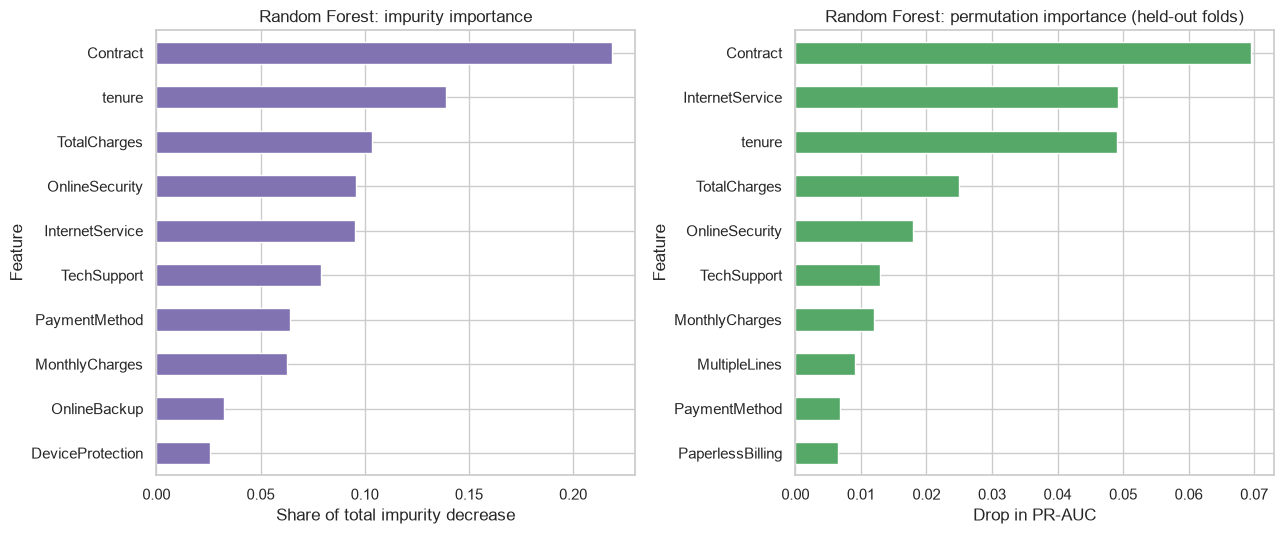

num__MonthlyCharges                   -1.32
num__tenure                           -1.29
cat__InternetService_DSL              -0.98
cat__Contract_Two year                -0.87
cat__MultipleLines_No phone service   -0.58
cat__InternetService_No               -0.52
cat__StreamingTV_Yes                   0.29
cat__StreamingMovies_Yes               0.29
cat__PaperlessBilling_Yes              0.37
cat__Contract_Month-to-month           0.49
num__TotalCharges                      0.57
cat__InternetService_Fiber optic       0.90
Name: LogReg coefficient, dtype: float64

In [22]:
rf_fit = tuned_models['RandomForest'].fit(X_train, y_train)
rf_names = rf_fit.named_steps['pre'].get_feature_names_out()
rf_impurity = aggregate_to_original(pd.Series(rf_fit.named_steps['model'].feature_importances_, index=rf_names),list(X_train.columns))

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
rf_impurity.head(10)[::-1].plot(kind='barh', ax=axes[0], color='#8172B2')
axes[0].set_title('Random Forest: impurity importance')
axes[0].set_xlabel('Share of total impurity decrease')
axes[0].set_ylabel('Feature')
perm['RandomForest']['mean'].head(10)[::-1].plot(kind='barh', ax=axes[1], color='#55A868')
axes[1].set_title('Random Forest: permutation importance (held-out folds)')
axes[1].set_xlabel('Drop in PR-AUC')
axes[1].set_ylabel('Feature')
save_fig('21_rf_impurity_vs_permutation')
plt.show()

lr_fit = tuned_pipeline('LogReg', best_params['LogReg'], X_train).fit(X_train, y_train)
coef = pd.Series(lr_fit.named_steps['model'].coef_[0],
                 index=lr_fit.named_steps['pre'].get_feature_names_out()).sort_values()
display(pd.concat([coef.head(6), coef.tail(6)]).round(2).rename('LogReg coefficient'))

**Result:** impurity importance ranks `TotalCharges` 3rd and `InternetService` 5th; permutation on held-out data ranks them 4th and 2nd, and `PaymentMethod` drops from 7th to 9th. Impurity importance favors numeric and many-category columns, so trust the permutation version.

LogReg coefficients agree on direction: fiber optic, month-to-month and paperless billing raise churn; DSL, a two-year contract and long tenure lower it. As before, `MonthlyCharges` (negative) and `TotalCharges` (positive) have opposite signs because they are correlated with `tenure` and the service columns; read them together, not alone.

## 13. Business reading of the top 5 features

| Feature | What the data shows | Reading / action |
|---|---|---|
| `tenure` | churn 52.9% in the first 6 months, 9.5% after 4 years | The first months are the danger zone: onboarding and early check-ins. |
| `Contract` | month-to-month 42.7%, one-year 11.3%, two-year 2.8% | No commitment means easy exit: offer incentives to move to a longer contract. |
| `InternetService` | fiber 41.9%, DSL 19.0%, no internet 7.4% | Fiber customers leave most: check price, service quality and competitors for fiber. |
| `MonthlyCharges` | churners pay 74.4 vs 61.3 on average | Higher bills raise risk; correlated with fiber and extra services, so it is not a pure price effect. |
| `TotalCharges` | about `tenure` x `MonthlyCharges` (correlation 0.83) | Adds little beyond the two features that build it. |

These are associations, not causes. An A/B test of the retention offers is needed to measure causal effects.

## 14. Final evaluation on the test set (used once)

The final model is refit on the full train set and the threshold comes from the train OOF analysis above. Nothing is changed after seeing these numbers.

In [23]:
final_model = tuned_pipeline(final_name, best_params[final_name], X_train).fit(X_train, y_train)
test_proba = final_model.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= final_threshold).astype(int)

def summarize(y, proba, pred):
    c = confusion_counts(y, pred)
    return {
        'precision': precision_score(y, pred, zero_division=0),
        'recall': recall_score(y, pred),
        'f1': f1_score(y, pred),
        'roc_auc': roc_auc_score(y, proba),
        'pr_auc': average_precision_score(y, proba),
        'accuracy': accuracy_score(y, pred),
        'profit_per_1000': expected_profit(c['tp'], c['fp'], assump) / len(y) * 1000,
        **c,
    }


test_scores = summarize(y_test, test_proba, test_pred)
keys = ['precision', 'recall', 'f1', 'pr_auc', 'roc_auc', 'profit_per_1000']
rng = np.random.default_rng(RANDOM_STATE)
y_arr = y_test.to_numpy()
boot = []
for _ in range(1000):
    idx = rng.integers(0, len(y_arr), len(y_arr))
    s = summarize(y_arr[idx], test_proba[idx], test_pred[idx])
    boot.append([s[k] for k in keys])
lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)

display(pd.DataFrame({'test': [test_scores[k] for k in keys],'95% CI low': lo, '95% CI high': hi}, index=keys).round(3))
print({k: test_scores[k] for k in ['tp', 'fp', 'fn', 'tn']})


rule = (X_test['Contract'] == 'Month-to-month').astype(int).to_numpy()
ref = pd.DataFrame({
    'Rule: month-to-month': summarize(y_test, rule, rule),
    'Final model @ 0.5 (reference)': summarize(
        y_test, test_proba, (test_proba >= 0.5).astype(int)),
    'Final model @ chosen threshold': test_scores,
}).T[['precision', 'recall', 'f1', 'roc_auc', 'pr_auc', 'profit_per_1000']].round(3)
display(ref)

pos = int(y_test.sum())
print('contact everyone: profit per 1000 =',round(expected_profit(pos, len(y_test) - pos, assump) / len(y_test) * 1000))

with open(REPORT_DIR / 'final_model.json', 'w') as f:
    json.dump({
        'model': final_name,
        'params': best_params[final_name],
        'threshold': final_threshold,
        'assumptions': {'value': assump.value, 'cost': assump.cost,
                        'success_rate': assump.success_rate},
        'test': {k: round(float(v), 4) for k, v in test_scores.items()},
    }, f, indent=2)

,test,95% CI low,95% CI high
precision,0.359,0.329,0.387
recall,0.987,0.974,0.997
f1,0.526,0.493,0.555
pr_auc,0.631,0.579,0.683
roc_auc,0.842,0.819,0.863
profit_per_1000,2803.407,-461.320,5856.104


{'tp': 369, 'fp': 659, 'fn': 5, 'tn': 376}


,precision,recall,f1,roc_auc,pr_auc,profit_per_1000
Rule: month-to-month,0.426,0.880,0.574,0.725,0.406,7594.038
Final model @ 0.5 (reference),0.661,0.564,0.609,0.842,0.631,11142.654
Final model @ chosen threshold,0.359,0.987,0.526,0.842,0.631,2803.407


contact everyone: profit per 1000 = -10185


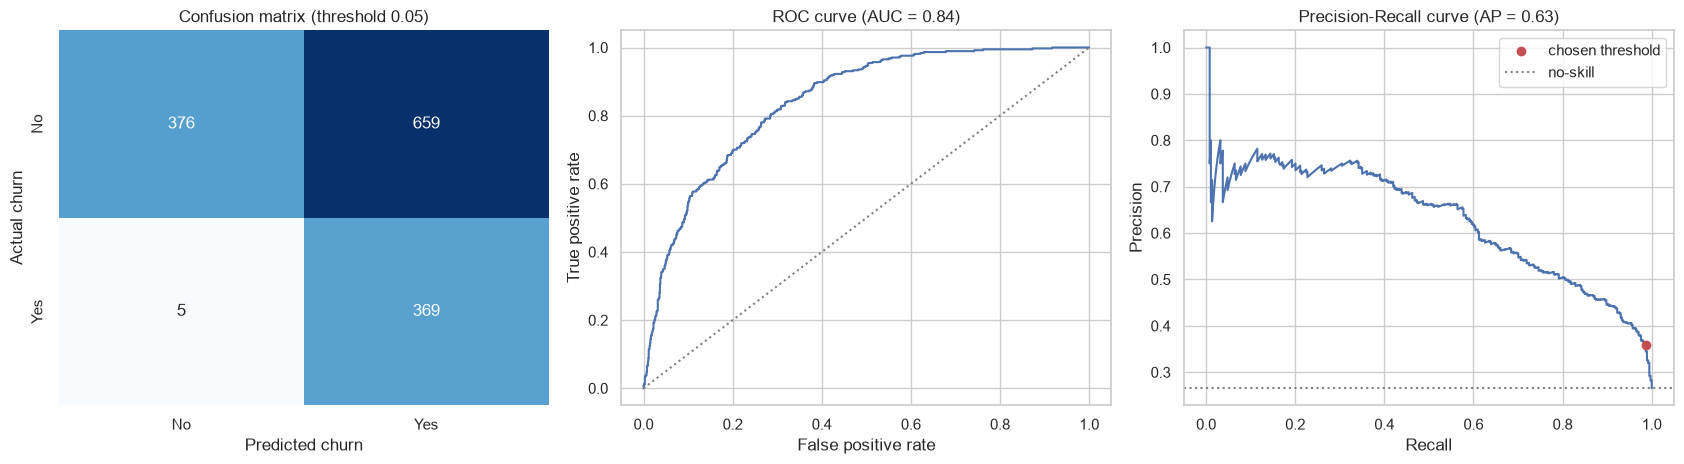

In [24]:
cm = np.array([[test_scores['tn'], test_scores['fp']],[test_scores['fn'], test_scores['tp']]])
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'], ax=axes[0])
axes[0].set_title(f'Confusion matrix (threshold {final_threshold:.2f})')
axes[0].set_xlabel('Predicted churn')
axes[0].set_ylabel('Actual churn')
fpr, tpr, _ = roc_curve(y_test, test_proba)
axes[1].plot(fpr, tpr)
axes[1].plot([0, 1], [0, 1], color='gray', linestyle=':')
axes[1].set_title(f"ROC curve (AUC = {test_scores['roc_auc']:.2f})")
axes[1].set_xlabel('False positive rate')
axes[1].set_ylabel('True positive rate')

prec, rec, _ = precision_recall_curve(y_test, test_proba)
axes[2].plot(rec, prec)
axes[2].scatter([test_scores['recall']], [test_scores['precision']],color='#C44E52', zorder=3, label='chosen threshold')
axes[2].axhline(y_test.mean(), color='gray', linestyle=':', label='no-skill')
axes[2].set_title(f"Precision-Recall curve (AP = {test_scores['pr_auc']:.2f})")
axes[2].set_xlabel('Recall')
axes[2].set_ylabel('Precision')
axes[2].legend()
save_fig('22_test_evaluation')
plt.show()

**Result (test set, 1,409 customers, threshold 0.33):** precision 0.54, recall 0.72, F1 0.61, ROC-AUC 0.84, PR-AUC 0.63. The model finds 269 of 374 churners (105 missed) with 233 false alarms.
